# What the community calls a bomb

`results/bombs/consensus_bombs.csv` is a hand-curated list of the cards Limited players called bombs in each of our
19 sets, compiled from set reviews, tier lists and retrospectives. Sources and method are in
`results/bombs/consensus_bombs_sources.md`. This notebook asks what those cards have in common, and what their
17Lands numbers look like next to the rest of the set.

**Groups.** Each card in a set lands in exactly one group:

* **bomb: pre & post**: called a bomb in set reviews *and* confirmed after release (`when = both`).
* **bomb: post only**: recognized as a bomb only after release, mostly from data-driven write-ups.
* **bomb: pre only**: called a bomb in reviews, with no post-release confirmation found.
* **hyped, downgraded**: hyped before release, then downgraded, or the metrics disagree (`agreement = contested`).
* **other rare/mythic**, **uncommon**, **common**: every other card in the set.

Only `strong` and `moderate` agreement counts as "called a bomb". The handful of `weak` mentions (a single source, or a
search snippet) are left out of every group.

**Stats.** All of them are Premier Draft:

* **norm GIH**: shrunk normalized GIH WR in pp above the set's average, from the bombs notebook.
* **IWD**: shrunk improvement when drawn, in pp.
* **z**: robust z of norm GIH within the set. The bombs notebook's outlier fence sits at z = 2.70.
* **ATA**: average pick (1–14 within a pack) at which the card was taken.
* **early take**: share of picks 1–3 of a pack where the card was in the pack and got taken.

Pick stats need draft logs, so they're missing for NEO and ONE. TLA and TMT logs have no pack 1 pick 1. That pushes
those sets' bomb ATAs slightly later, and their "early take" covers picks 2–3 of pack 1.

Post-release community ratings are often *built from* 17Lands win rates, so the "post" groups agreeing with our
numbers is partly circular. The honest test of opinion against data is the **pre only** and **hyped** groups.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import COLORS, card_metadata

BOMBS = ROOT / "results" / "bombs"
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
FENCE_Z = 0.6745 + 1.5 * 1.349   # the bombs notebook's Tukey fence, in robust z

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60)

GROUPS = ["bomb: pre & post", "bomb: post only", "bomb: pre only", "hyped, downgraded",
          "other rare/mythic", "uncommon", "common"]
G_COLOR = dict(zip(GROUPS, [BLUE, AQUA, VIOLET, ORANGE, GRAY, GRAY, GRAY]))

## 1. Cards, metadata, pick stats, and group labels

One row per card per set, joining:

* the bombs notebook's cached ratings (`results/bombs/{set}.PremierDraft.cards.parquet`),
* card metadata (rarity, mana value, type line, colors, and whether the card is from a bonus sheet),
* pick stats from the draft logs, cached to `results/bombs/pick_stats.parquet`,
* the curated consensus list, joined on the matched data name.

In [2]:
TYPE_ORDER = ["Planeswalker", "Battle", "Creature", "Instant", "Sorcery", "Enchantment", "Artifact", "Land"]


def load_set(s):
    d = pl.read_parquet(BOMBS / f"{s}.PremierDraft.cards.parquet")
    iqr = d["norm_eb"].quantile(0.75) - d["norm_eb"].quantile(0.25)
    d = d.with_columns(((pl.col("norm_eb") - pl.col("norm_eb").median()) / (iqr / 1.349)).alias("z"),
                       pl.col("norm_eb").rank(descending=True, method="min").cast(pl.Int64).alias("data_rank"),
                       pl.len().alias("set_cards"))
    meta = card_metadata(d["name"].to_list(), s).drop("rarity")
    return d.join(meta, on="name", how="left")


def main_type(t):
    # the first matching type in TYPE_ORDER, so an artifact creature counts as a creature
    return next((k for k in TYPE_ORDER if k in t), "Other")


def pick_stats(s):
    path = ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet"
    lf = pl.scan_parquet(path)
    cols = [c for c in lf.collect_schema().names() if c.startswith("pack_card_")]
    ata = (lf.group_by("pick").agg((pl.col("pick_number") + 1).mean().alias("ata"), pl.len().alias("n_picked"))
           .rename({"pick": "name"}))
    early = lf.filter(pl.col("pick_number") <= 2)
    taken = early.group_by("pick").agg(pl.len().alias("n_taken_early")).rename({"pick": "name"})
    seen = (early.select([(pl.col(c) > 0).sum().alias(c[len("pack_card_"):]) for c in cols]).collect()
            .transpose(include_header=True, header_name="name", column_names=["n_seen_early"]))
    return (ata.join(taken, on="name", how="left").collect().join(seen, on="name", how="left")
            .with_columns((pl.col("n_taken_early") / pl.col("n_seen_early")).alias("take_early"), pl.lit(s).alias("set")))


PICKS = BOMBS / "pick_stats.parquet"
if PICKS.exists():
    picks = pl.read_parquet(PICKS)
else:
    picks = pl.concat([pick_stats(s) for s in SETS if (ROOT / "data" / "parquet" / f"{s}.PremierDraft.parquet").exists()],
                      how="diagonal_relaxed")
    picks.write_parquet(PICKS)

cons = (pl.read_csv(BOMBS / "consensus_bombs_vs_data.csv").filter(pl.col("data_name").is_not_null())
        .select("set", pl.col("data_name").alias("name"), "when", "agreement"))

cards = (pl.concat([load_set(s) for s in SETS], how="diagonal_relaxed")
         .join(picks.select("set", "name", "ata", "take_early"), on=["set", "name"], how="left")
         .join(cons, on=["set", "name"], how="left")
         .with_columns(pl.col("types").map_elements(main_type, return_dtype=pl.Utf8).alias("main_type"),
                       pl.sum_horizontal([pl.col(c).cast(pl.Int8) for c in COLORS]).alias("n_colors")))
cards = cards.with_columns(
    pl.when(pl.col("agreement") == "contested").then(pl.lit("hyped, downgraded"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "both")).then(pl.lit("bomb: pre & post"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "post")).then(pl.lit("bomb: post only"))
    .when(pl.col("agreement").is_in(["strong", "moderate"]) & (pl.col("when") == "pre")).then(pl.lit("bomb: pre only"))
    .when(pl.col("agreement") == "weak").then(None)
    .when(pl.col("rarity").is_in(["rare", "mythic"])).then(pl.lit("other rare/mythic"))
    .when(pl.col("rarity") == "uncommon").then(pl.lit("uncommon"))
    .when(pl.col("rarity") == "common").then(pl.lit("common"))
    .otherwise(None).alias("group"))
g = cards.filter(pl.col("group").is_not_null())
print(f"{cards.height} cards over {len(SETS)} sets;",
      dict(g.group_by("group").len().iter_rows()))

5568 cards over 19 sets; {'bomb: pre only': 44, 'uncommon': 1901, 'bomb: post only': 52, 'bomb: pre & post': 92, 'hyped, downgraded': 28, 'common': 1781, 'other rare/mythic': 1647}


## 2. What kind of card gets called a bomb?

The share of each group by rarity, and how often the cards are bonus-sheet reprints, creatures, multicolored, or
expensive. "Called a bomb" pools the three bomb groups.

In [3]:
called = pl.col("group").str.starts_with("bomb")
prof = (g.with_columns(pl.when(called).then(pl.lit("called a bomb")).otherwise(pl.col("group")).alias("g"))
        .group_by("g").agg(
            pl.len().alias("cards"),
            (pl.col("rarity") == "mythic").mean().alias("mythic"),
            (pl.col("rarity") == "rare").mean().alias("rare"),
            (pl.col("rarity").is_in(["uncommon", "common"])).mean().alias("unc/common"),
            pl.col("is_bonus").mean().alias("bonus sheet"),
            pl.col("is_creature").mean().alias("creature"),
            (pl.col("n_colors") >= 2).mean().alias("multicolor"),
            (pl.col("n_colors") == 0).mean().alias("colorless"),
            pl.col("mana_value").median().alias("median MV"),
            (pl.col("mana_value") >= 5).mean().alias("MV 5+"))
        .sort(pl.col("g").replace_strict({k: i for i, k in enumerate(["called a bomb"] + GROUPS)}, default=99)))
with pl.Config(float_precision=2):
    display(prof)

g,cards,mythic,rare,unc/common,bonus sheet,creature,multicolor,colorless,median MV,MV 5+
str,u32,f64,f64,f64,f64,f64,f64,f64,f32,f64
"""called a bomb""",188,0.45,0.53,0.02,0.11,0.63,0.28,0.04,4.50,0.50
"""hyped, downgraded""",28,0.50,0.50,0.00,0.00,0.57,0.29,0.07,4.00,0.36
"""other rare/mythic""",1647,0.26,0.74,0.00,0.20,0.53,0.31,0.09,3.00,0.22
"""uncommon""",1901,0.00,0.00,1.00,0.06,0.54,0.21,0.06,3.00,0.17
"""common""",1781,0.00,0.00,1.00,0.02,0.52,0.11,0.07,2.00,0.13


### 2a. Card types and mana values

Of the cards called a bomb, the share by main card type (an artifact creature counts as a creature) and by mana value,
next to other rares and mythics.

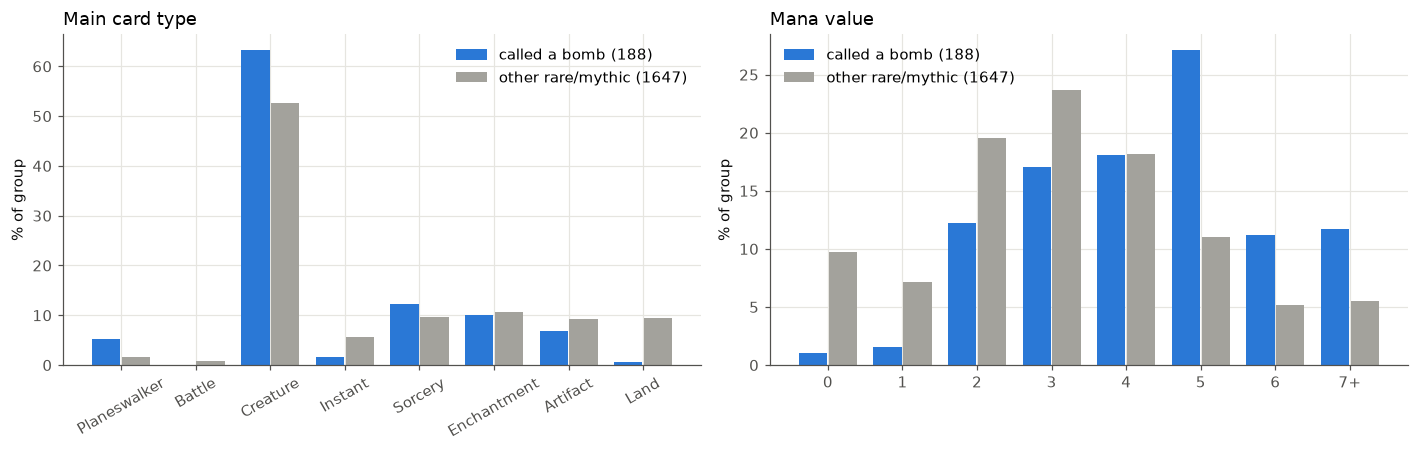

In [4]:
cmp = g.filter(called | (pl.col("group") == "other rare/mythic")).with_columns(
    pl.when(called).then(pl.lit("called a bomb")).otherwise(pl.lit("other rare/mythic")).alias("g"),
    pl.col("mana_value").clip(0, 7).cast(pl.Int64).alias("mv"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, order in [(axes[0], "main_type", TYPE_ORDER), (axes[1], "mv", list(range(8)))]:
    order = [k for k in order if k in set(cmp[col].to_list())]
    x = np.arange(len(order))
    for dx, (lab, c) in zip((-0.2, 0.2), [("called a bomb", BLUE), ("other rare/mythic", GRAY)]):
        sub = cmp.filter(pl.col("g") == lab)
        share = [(sub[col] == k).mean() * 100 for k in order]
        ax.bar(x + dx, share, width=0.38, color=c, label=f"{lab} ({sub.height})")
    ax.set_xticks(x, [str(k) if k != 7 else "7+" for k in order] if col == "mv" else order,
                  rotation=0 if col == "mv" else 30)
    ax.set_ylabel("% of group"); ax.legend()
axes[0].set_title("Main card type", loc="left"); axes[1].set_title("Mana value", loc="left")
plt.tight_layout(); plt.show()

## 3. Their numbers

Medians per group. `above fence` is the share above the bombs notebook's outlier cutoff (z > 2.70).

In [5]:
stats = (g.group_by("group").agg(
            pl.len().alias("cards"),
            (pl.col("gih_wr") * 100).median().alias("GIH WR %"),
            pl.col("norm_eb").median().alias("norm GIH pp"),
            pl.col("iwd_eb").median().alias("IWD pp"),
            pl.col("z").median().alias("z"),
            (pl.col("z") > FENCE_Z).mean().alias("above fence"),
            pl.col("data_rank").median().alias("set rank"),
            pl.col("ata").median().alias("ATA"),
            pl.col("take_early").median().alias("early take"))
         .sort(pl.col("group").replace_strict({k: i for i, k in enumerate(GROUPS)})))
with pl.Config(float_precision=2):
    display(stats)

group,cards,GIH WR %,norm GIH pp,IWD pp,z,above fence,set rank,ATA,early take
str,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""bomb: pre & post""",92,64.26,9.41,10.60,2.75,0.52,5.00,1.50,0.72
"""bomb: post only""",52,65.09,9.53,11.22,2.61,0.44,5.00,1.78,0.69
"""bomb: pre only""",44,62.95,7.56,9.72,2.20,0.16,11.00,1.83,0.63
"""hyped, downgraded""",28,59.61,4.36,5.76,1.24,0.00,38.50,1.84,0.55
"""other rare/mythic""",1647,56.27,1.16,3.46,0.29,0.01,113.00,3.01,0.29
"""uncommon""",1901,55.08,0.05,1.63,-0.06,0.00,156.00,6.14,0.09
"""common""",1781,54.60,-0.51,0.68,-0.20,0.00,167.00,8.84,0.02


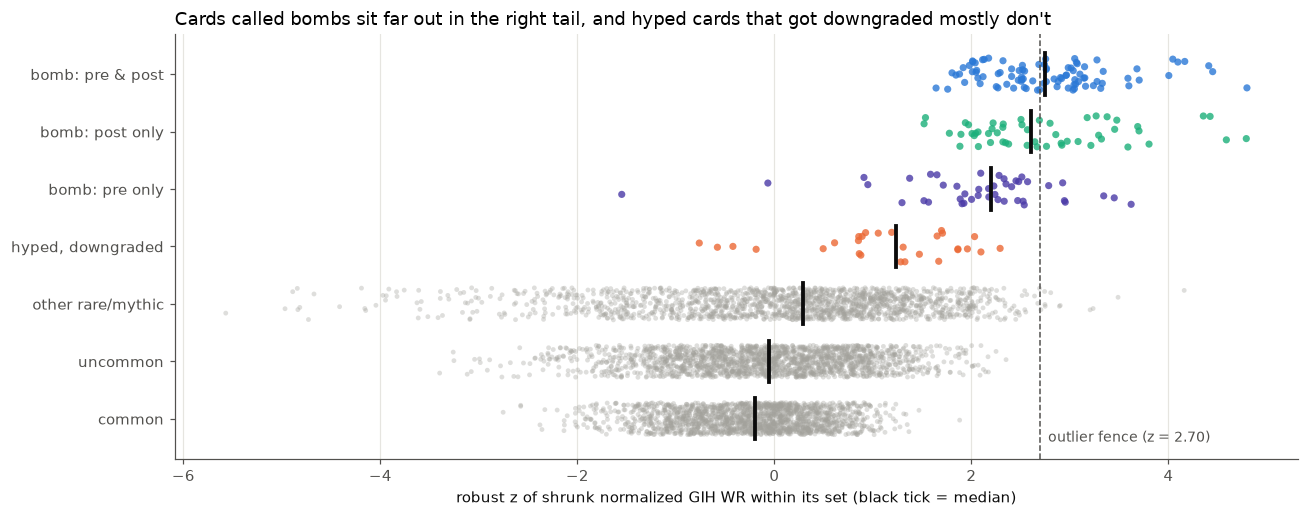

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8))
rng = np.random.default_rng(0)
for i, grp in enumerate(GROUPS):
    z = g.filter(pl.col("group") == grp)["z"].to_numpy()
    y = i + rng.uniform(-0.28, 0.28, len(z))
    ax.scatter(z, y, s=10 if len(z) > 500 else 22, color=G_COLOR[grp], alpha=0.35 if len(z) > 500 else 0.8,
               edgecolor="none")
    ax.plot([np.median(z)] * 2, [i - 0.36, i + 0.36], color=INK, lw=2.5)
ax.axvline(FENCE_Z, color=MUTED, lw=1, ls="--")
ax.text(FENCE_Z + 0.08, len(GROUPS) - 0.6, "outlier fence (z = 2.70)", color=MUTED, fontsize=9)
ax.set_yticks(range(len(GROUPS)), GROUPS); ax.invert_yaxis()
ax.set_xlabel("robust z of shrunk normalized GIH WR within its set (black tick = median)")
ax.set_title("Cards called bombs sit far out in the right tail, and hyped cards that got downgraded mostly don't",
             loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 3a. Do drafters take them like bombs?

Rares and mythics only: average pick taken vs rating. The question is whether drafters' picks (ATA) separated the
real bombs from the hyped ones, or treated them the same.

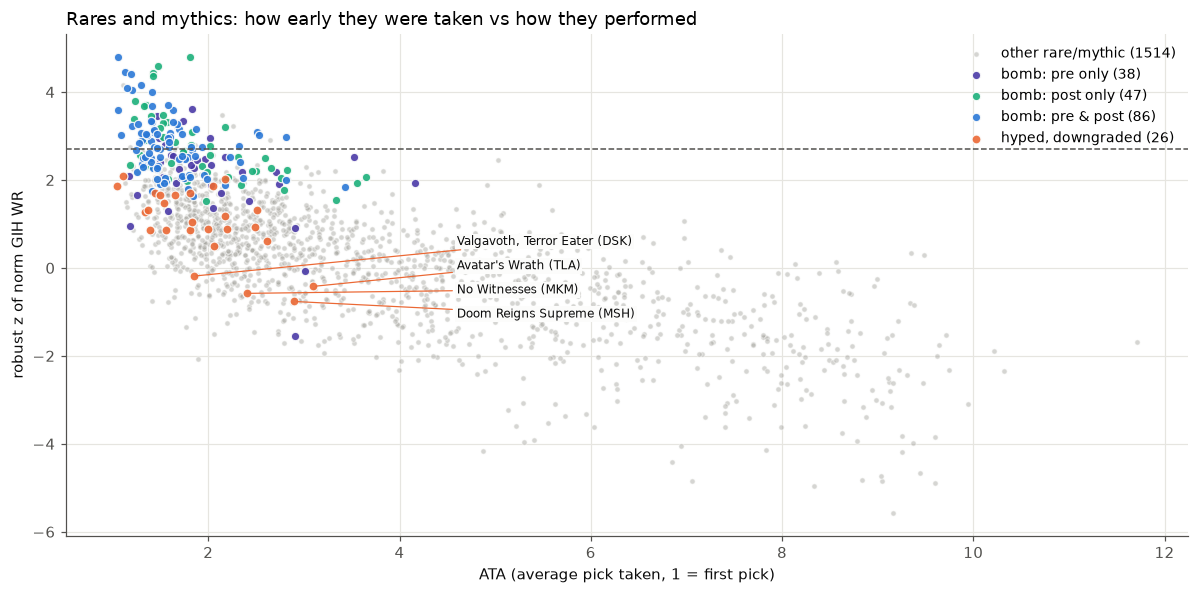

Spearman rank correlation of ATA with z, rares/mythics: -0.755


In [7]:
rm = g.filter(pl.col("rarity").is_in(["rare", "mythic"]) | called | (pl.col("group") == "hyped, downgraded")
             ).filter(pl.col("ata").is_not_null())
fig, ax = plt.subplots(figsize=(11, 5.5))
for grp, size in [("other rare/mythic", 12), ("bomb: pre only", 30), ("bomb: post only", 30),
                  ("bomb: pre & post", 30), ("hyped, downgraded", 34)]:
    sub = rm.filter(pl.col("group") == grp)
    ax.scatter(sub["ata"], sub["z"], s=size, color=G_COLOR[grp], alpha=0.45 if grp.startswith("other") else 0.9,
               edgecolor=SURFACE, linewidth=0.8, label=f"{grp} ({sub.height})")
ax.axhline(FENCE_Z, color=MUTED, lw=1, ls="--")
# label the hyped cards that played below the set median, stacked in a column to the right
for k, r in enumerate(rm.filter((pl.col("group") == "hyped, downgraded") & (pl.col("z") < 0)).sort("z", descending=True)
                      .iter_rows(named=True)):
    ax.annotate(f"{r['name']} ({r['set']})", (r["ata"], r["z"]), xytext=(4.6, 0.6 - 0.55 * k), textcoords="data",
                fontsize=8, color=INK, va="center", bbox={"fc": SURFACE, "ec": "none", "pad": 1},
                arrowprops={"arrowstyle": "-", "color": ORANGE, "lw": 0.8})
ax.set_xlabel("ATA (average pick taken, 1 = first pick)"); ax.set_ylabel("robust z of norm GIH WR")
ax.set_title("Rares and mythics: how early they were taken vs how they performed", loc="left")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()
print("Spearman rank correlation of ATA with z, rares/mythics:",
      round(rm.select(pl.corr("ata", "z", method="spearman")).item(), 3))

## 4. Every card called a bomb, with its numbers

Sorted by z within each group, and saved to `results/bombs/consensus_bombs_stats.csv`.

In [8]:
cols = ["set", "name", "rarity", "main_type", "mana_value", "group", "agreement", "gih_wr", "norm_eb", "iwd_eb", "z",
        "data_rank", "set_cards", "ata", "take_early", "is_bonus"]
tbl = (g.filter(called | (pl.col("group") == "hyped, downgraded")).select(cols)
       .with_columns((pl.col("gih_wr") * 100).round(1), pl.col("norm_eb").round(1), pl.col("iwd_eb").round(1),
                     pl.col("z").round(2), pl.col("ata").round(2), pl.col("take_early").round(2))
       .sort(pl.col("group").replace_strict({k: i for i, k in enumerate(GROUPS)}), pl.col("z"), descending=[False, True]))
tbl.write_csv(BOMBS / "consensus_bombs_stats.csv")
with pl.Config(tbl_rows=300, tbl_width_chars=250):
    display(tbl.drop("set_cards", "is_bonus", "agreement"))

set,name,rarity,main_type,mana_value,group,gih_wr,norm_eb,iwd_eb,z,data_rank,ata,take_early
str,str,str,str,f32,str,f64,f64,f64,f64,i64,f64,f64
"""TDM""","""Ugin, Eye of the Storms""","""mythic""","""Planeswalker""",7.0,"""bomb: pre & post""",68.5,13.5,17.1,4.8,1,1.06,0.96
"""LCI""","""Bonehoard Dracosaur""","""mythic""","""Creature""",5.0,"""bomb: pre & post""",70.3,14.9,16.4,4.45,1,1.13,0.91
"""DSK""","""Overlord of the Mistmoors""","""mythic""","""Creature""",7.0,"""bomb: pre & post""",68.1,13.6,15.9,4.41,1,1.19,0.84
"""DFT""","""Sab-Sunen, Luxa Embodied""","""mythic""","""Creature""",5.0,"""bomb: pre & post""",68.0,13.0,14.6,4.17,1,1.29,0.86
"""MKM""","""Aurelia's Vindicator""","""mythic""","""Creature""",4.0,"""bomb: pre & post""",68.4,13.3,13.8,4.1,1,1.15,0.92
"""LCI""","""Aclazotz, Deepest Betrayal""","""mythic""","""Creature""",5.0,"""bomb: pre & post""",68.9,13.5,17.1,4.04,2,1.2,0.79
"""WOE""","""Gruff Triplets""","""rare""","""Creature""",6.0,"""bomb: pre & post""",68.9,13.7,16.9,4.0,1,1.41,0.78
"""OTJ""","""Bonny Pall, Clearcutter""","""rare""","""Creature""",6.0,"""bomb: pre & post""",66.2,12.1,15.9,3.7,1,1.58,0.75
"""DSK""","""Valgavoth's Onslaught""","""rare""","""Sorcery""",1.0,"""bomb: pre & post""",65.9,11.4,14.5,3.68,2,1.41,0.84


## Takeaways

These were written from the run on 2026-10-07.

* **What gets called a bomb.**
  * Almost always a rare or mythic: 98% of the list. Only four are uncommons: Dream Beavers, Mighty Mutanimals,
    Imodane's Recruiter, and Justice, Vance Astrovik.
  * Mythics are overrepresented: 45% of the list, against 26% of other rares and mythics.
  * Mostly creatures, and expensive ones. 63% are creatures, the median mana value is 4.5 (other rares: 3), and half
    cost 5 or more. Five mana is the single most common cost.
  * Planeswalkers are over-represented, and cheap spells and lands almost never make the list. The archetype is a
    5-drop that takes over the board or grinds card advantage.
* **Their numbers.** Cards confirmed after release (pre & post, or post only) have a median GIH WR around 64–65%. That
  is about 9.5pp above the set's average game and about 8pp above the median other rare. They rank around 5th in
  their set, and roughly half clear the outlier fence. Drafters take them at pick 1.5–1.8 on average, and take them
  about 70% of the time they appear in picks 1–3.
* **Pre-release hype is a weaker signal.**
  * "Pre only" cards still sit well above other rares: median rank 11, z 2.2.
  * The 28 cards that got downgraded have median rank 38 and z 1.2, and none clears the fence. A few played like
    filler: Doom Reigns Supreme, No Witnesses, Avatar's Wrath, Valgavoth.
  * Drafters still took the downgraded cards almost as early as the real bombs: ATA 1.84 vs 1.5–1.8.
* **Picks track performance well overall.** Across all rares and mythics, Spearman ρ(ATA, z) ≈ −0.76. Separating a
  top-5 bomb from a top-30 hyped rare is the part drafters get wrong.
* **Caveat.** Post-release community grades are often built from 17Lands data, so the "post" groups agreeing with our
  numbers is partly by construction.